In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kaushaltiwari/tiny-shakespeare/tiny-shakespeare.txt


In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

# print(os.getenv("NGROK_AUTHTOKEN"))

True

In [4]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from pathlib import Path

path = "/kaggle/input/datasets/kaushaltiwari/tiny-shakespeare/tiny-shakespeare.txt"
file = Path(path)

device = "cuda" if torch.cuda.is_available() else "cpu"
# print(torch.cuda.get_device_properties())

with file.open("r") as f:
    txt = f.read()

In [5]:
vocab = sorted(list(set(txt)))
stoi = {v:k for k, v in enumerate(vocab)}
itos = {v:k for k, v in stoi.items()}

encoder = lambda s: [stoi[c] for c in s]
decoder = lambda l: "".join([itos[t] for t in l])

data = torch.tensor(encoder(txt), dtype=torch.long)
f"{len(data)/1_000_000:.2f} M tokens"

'1.12 M tokens'

In [6]:
n1 = int(data.shape[0] * 0.8)
n2 = int(data.shape[0] * 0.9)

train_data = data[:n1]
test_data = data[n1:n2]
valid_data = data[n2:]


print(len(train_data), len(test_data), len(valid_data))

892315 111539 111540


In [7]:


def build_ds(data, batch_size, block_size):
    
    ix = torch.randint(0, len(data) - block_size, (batch_size, ))
    X = torch.stack([data[i:i+block_size] for i in ix])
    Y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    
    return  X, Y



# X, Y = build_ds(valid_data, batch_size, block_size)

In [8]:
import torch
import torch.nn as nn



class RotatoryPositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len = 50000):
        super().__init__()
        pos = torch.arange(0, max_len).unsqueeze(1)
        ix = torch.arange(0, d_model//2).unsqueeze(0)
        omega = 1e4 ** (-2 * ix/d_model)
        angles = pos * omega
        self.register_buffer("cos", angles.cos())
        self.register_buffer("sin", angles.sin())

    def forward(self, x):
        T= x.shape[-2]
        cos, sin = self.cos[:T], self.sin[:T]

        X, Y = x[..., 0::2], x[..., 1::2] # x-ords, y-ords for every token
     
        Xn =  X * cos[:T] + Y * sin[:T] # [ cosQ sinQ ]  [X]
        Yn = -X * sin[:T] + Y * cos[:T] # [-sinQ cosQ ] [Y]
        
        out = torch.empty_like(x)
        out[..., 0::2] = Xn
        out[..., 1::2] = Yn

        return out
        

class GroupedQueryAttention(nn.Module):

    def __init__(self, block_size, d_model, heads, groups, dropout):
        super().__init__()
        
        self.hs = d_model // heads
        self.rps = heads // groups
        
        self.Wqs = nn.ModuleList([nn.Linear(d_model, self.hs) for _ in range(heads)])
        self.Wks = nn.ModuleList([nn.Linear(d_model, self.hs) for _ in range(groups)])
        self.Wvs = nn.ModuleList([nn.Linear(d_model, self.hs) for _ in range(groups)])
        self.rope = RotatoryPositionalEncoding(self.hs, block_size)
        self.Wo = nn.Linear(heads * self.hs, d_model)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape # Batch, block_size, d_models (B, T, C)

        Q = self.rope(torch.stack([Wq(x) for Wq in self.Wqs]))
        K = torch.stack([Wk(x) for Wk in self.Wks])
        V = torch.stack([Wv(x) for Wv in self.Wvs])

        K = self.rope(torch.repeat_interleave(K, self.rps, dim=0))
        V = torch.repeat_interleave(V, self.rps, dim=0)

        score = Q @ K.transpose(-2, -1) / self.hs ** 0.5
        score = score.masked_fill(self.mask[:T,  :T]==0, float("-inf"))
        probs = F.softmax(score, dim=-1)
        out = probs @ V
        out = out.permute(1, 2, 0, 3).reshape(B, T, -1)
        out  = self.dropout(self.Wo(out))

        return out
        


class FeedForward(nn.Module):

    def __init__(self, d_model, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(d_model, 4*d_model),
            nn.ReLU(),
            nn.Linear(4*d_model, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.layers(x)
        


class TransformerBlock(nn.Module):

    def __init__(self, d_model, n_heads, groups, block_size, dropout):
        super().__init__()
        head_size = d_model // n_heads
        self.gqa = GroupedQueryAttention(block_size, d_model, n_heads, groups, dropout)
        self.ff = FeedForward(d_model, dropout)
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)

    def forward(self, x):
        x = x + self.gqa(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class DecoderTransformerModel(nn.Module):

    def __init__(self, vocab_size, block_size, d_model, heads, groups, n_layers, dropout):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.Sequential(*[TransformerBlock(d_model, heads, groups, block_size, dropout) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.linear = nn.Linear(d_model, vocab_size)

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            # print(isinstance(module,nn.Linear))
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.normal_(module.bias, mean=0.0, std=0.02)

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)


    def forward(self, x, target = None):
        out = self.embeddings(x)
        out = self.blocks(out)
        logits = self.linear(self.ln(out))
        # B, T, C = logits.shape

        # loss = None
        # accuracy = None
        # if target:
        #     loss = F.cross_entropy(logits.view(B * T, -1), target.view(-1))
        #     accuracy = (logits.argmax(-1) == ys).float().mean()

            
        return logits #, loss, accuracy

In [9]:




@torch.no_grad()
def valid_loss(model, data, batch_size, block_size, device):
    xs, ys = build_ds(data, batch_size, block_size)
    xs, ys = xs.to(device), ys.to(device)
    logits = model(xs)
    B, T, C = logits.shape
    loss = F.cross_entropy(logits.view(B * T, -1), ys.view(-1))
    accuracy = (logits.argmax(-1) == ys).float().mean()

    return loss, accuracy

# ****EXPECTED: 4.174387269895637 for properly initialized weights****

In [10]:
loss_all = [] # keep track of all losses
valid_loss_all = [] #keep track of all validation losses
bench_valid_loss = 1e2
bench_valid_loss

100.0

In [12]:
# --------------------------------DATASET SPECIFIC PARAMETERS-----------------------------------------
block_size = 64 #No of tokens in a single sequence 
batch_size = 64#No of squences go in one pass.
vocab_size = len(vocab)
# --------------------------------MODEL SPECIFIC PARAMETERS-------------------------------------------
dropout = 0.2
d_model = 256
heads = 6
groups = 3
n_layers = 4


model = DecoderTransformerModel(vocab_size, block_size, d_model, heads, groups, n_layers, dropout).to(device)

params = 0
for p in model.parameters():
    params += (p.nelement())
    if p.grad:
        print(p.grad.shape)
        break
    # break

print(f"Parameters: {params/1e6:.2f}M")
print(f"Size of model: {(4 * params)/1024 ** 2: 0.2f}MB")


from torch.optim import Adam
import matplotlib.pyplot as plt


lr = 3e-4
optimizer = Adam(model.parameters(), lr=lr, weight_decay=0.01)

Parameters: 2.92M
Size of model:  11.13MB


In [ ]:
# %load_ext tensorboard
# %tensorboard --logdir=/kaggle/working

import time
from tqdm import tqdm


writer = SummaryWriter()
epochs = 10000
max_iter = 1000

lossi = []
valid_lossi = []
accuracyi = []
val_accuracyi = []
avg_times = []
lrsi = []

seconds = 0
ts = 0



for epoch in tqdm(range(epochs), desc="Training"):
    start = time.time()
    xs, ys = build_ds(train_data, batch_size, block_size)
    xs, ys = xs.to(device), ys.to(device)
    logits = model(xs)

    optimizer.zero_grad()
    loss = F.cross_entropy(logits.view(batch_size * block_size, -1), ys.view(-1))
    accuracy = (logits.argmax(dim=-1) == ys).float().mean()
    loss.backward()
    optimizer.step()

    val_loss, val_accuracy = valid_loss(model, valid_data, batch_size, block_size, device)   

    writer.add_scalar("Loss", loss, epoch)
    writer.add_scalar("Val Loss", val_loss, epoch)
    writer.add_scalar("Accuracy", accuracy, epoch)
    writer.add_scalar("Val Accuracy", val_accuracy, epoch)
    
    if val_loss < bench_valid_loss:
        PATH = "/kaggle/working/model_state_best.pth"
        torch.save(model.state_dict(), PATH)
        bench_valid_loss = val_loss.item()
        # i+=1

    
    if epoch%max_iter == 0:
        avg_time = seconds/60**0
        avg_times.append(seconds)
        seconds=0
        ts = 0
        print(f"[{epoch:4d}/{epochs}] | Loss: {loss:.3f} | Accuracy: {accuracy * 100:.1f}% | Val Loss: {val_loss:.3f} | Val Accuracy: {val_accuracy*100:.1f}% | Total Time: {avg_time:.2f}(s)")
        # lr = optimizer.param_groups[0]['lr']
        # lrsi.append(lr)
        
    optimizer.param_groups[0]['lr'] *= 0.999 if (lr > 1.5e-4 and epoch%2000 == 0 and epoch!=0) else (1 if epoch==0 else 0.9999)
        
    valid_lossi.append(val_loss.log10().item())
    lossi.append(loss.log10().item())
    accuracyi.append(accuracy.item())
    val_accuracyi.append(val_accuracy.item())
    end = time.time()
    seconds += end - start
    ts+=1
        
    
loss_all += lossi
valid_loss_all += valid_lossi

print("Best_val_loss:", bench_valid_loss)

writer.flush()
writer.close()

Training:   0%|          | 2/10000 [00:01<1:42:01,  1.63it/s]

[   0/10000] | Loss: 4.153 | Accuracy: 2.0% | Val Loss: 3.702 | Val Accuracy: 14.8% | Total Time: 0.00(s)


Training:  10%|█         | 1003/10000 [01:04<09:09, 16.37it/s]

[1000/10000] | Loss: 1.673 | Accuracy: 52.1% | Val Loss: 1.856 | Val Accuracy: 45.6% | Total Time: 63.91(s)


Training:  20%|██        | 2003/10000 [02:05<08:04, 16.50it/s]

[2000/10000] | Loss: 1.607 | Accuracy: 53.7% | Val Loss: 1.851 | Val Accuracy: 45.8% | Total Time: 60.43(s)


... (3 outputs left out)

[4000/10000] | Loss: 1.631 | Accuracy: 53.3% | Val Loss: 1.840 | Val Accuracy: 48.3% | Total Time: 60.17(s)


Training:  50%|█████     | 5003/10000 [05:06<05:01, 16.58it/s]

[5000/10000] | Loss: 1.631 | Accuracy: 53.0% | Val Loss: 1.855 | Val Accuracy: 47.0% | Total Time: 60.15(s)


Training:  51%|█████     | 5099/10000 [05:12<04:57, 16.47it/s]

In [26]:

checkpoints = {
    "model_state_dict": model.state_dict(),
    "loosi":lossi,
    "valid_lossi":valid_lossi,
    "loss_all":loss_all,
    "valid_loss_all":valid_loss_all,
    "best_valid_loss":bench_valid_loss
}


torch.save(checkpoints, "checkpoints.pth")

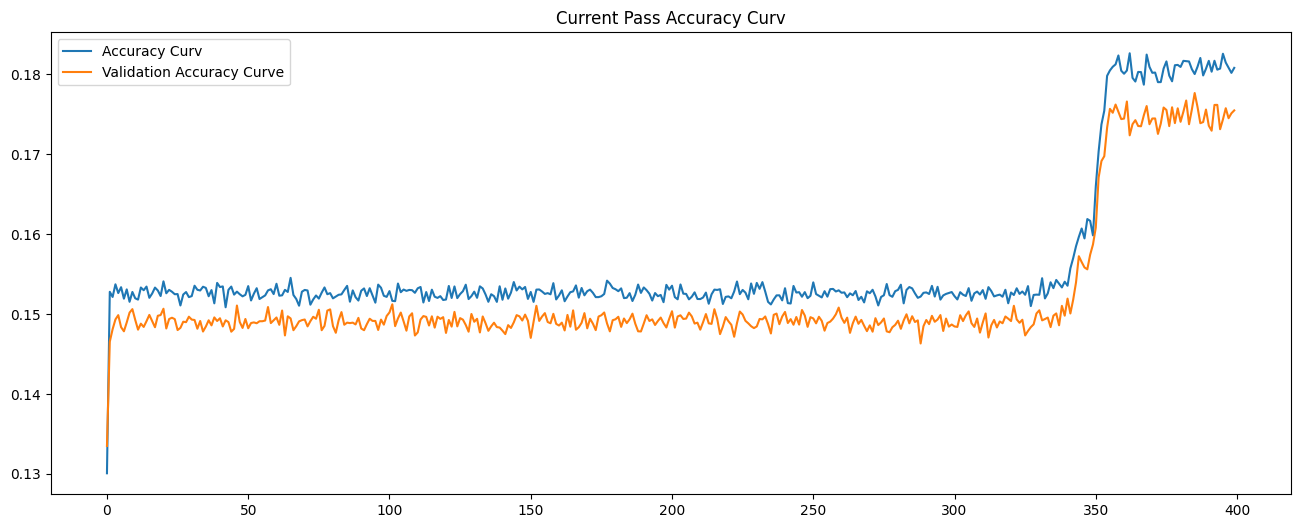

In [27]:
group_batch = 25
accuracyp = torch.tensor(accuracyi).view(len(accuracyi)//group_batch, group_batch).mean(dim=-1).tolist()
valid_accuracyp = torch.tensor(val_accuracyi).view(len(val_accuracyi)//group_batch, group_batch).mean(dim=-1).tolist()



plt.figure(figsize=(16, 6))
plt.plot(accuracyp, label="Accuracy Curv")
plt.plot(valid_accuracyp, label="Validation Accuracy Curve")
plt.title("Current Pass Accuracy Curv")
plt.legend()
plt.show()

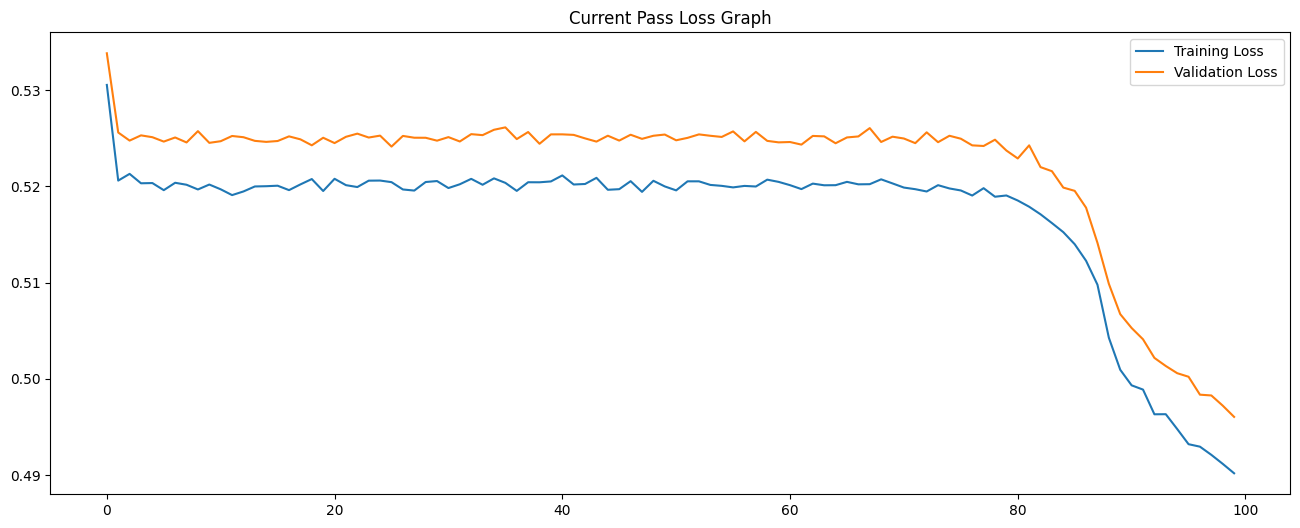

In [28]:
group_batch = 100
lossp = torch.tensor(lossi).view(len(lossi)//group_batch, group_batch).mean(dim=-1).tolist()
valid_lossp = torch.tensor(valid_lossi).view(len(valid_lossi)//group_batch, group_batch).mean(dim=-1).tolist()

plt.figure(figsize=(16, 6))
plt.plot(lossp, label="Training Loss")
plt.plot(valid_lossp, label="Validation Loss")
plt.title("Current Pass Loss Graph")
plt.legend()
plt.show()

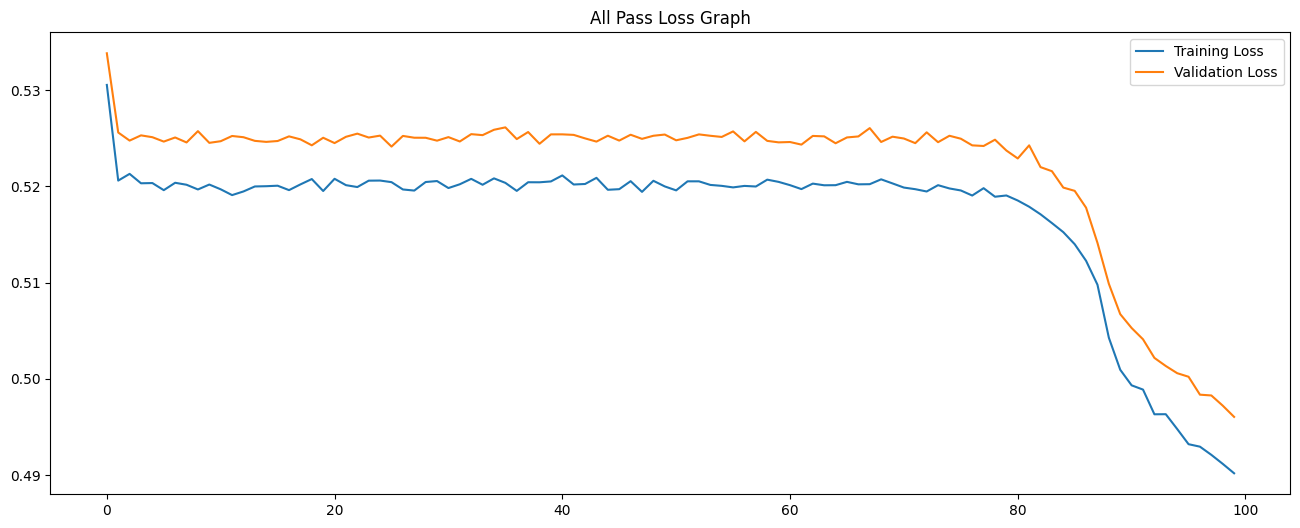

In [29]:
group_batch = 100
lossp = torch.tensor(loss_all).view(len(loss_all)//group_batch, group_batch).mean(dim=-1).tolist()
valid_lossp = torch.tensor(valid_loss_all).view(len(valid_loss_all)//group_batch, group_batch).mean(dim=-1).tolist()

plt.figure(figsize=(16, 6))
plt.plot(lossp, label="Training Loss")
plt.plot(valid_lossp, label="Validation Loss")
plt.title("All Pass Loss Graph")
plt.legend()
plt.show()

# other ways of observability
#weight initialization spiked loss to very low loss
#better way to train the model
#hyper parameter tunning


In [ ]:
model_path = "/kaggle/working/model_state_best.pth"
checkpoint = torch.load(model_path)
model.load_state_dict(checkpoint)
model.eval()

In [ ]:
g = torch.Generator(device=device).manual_seed(123456789)
start = encoder(".")
x = torch.tensor(start, device=device).view(1,1)
text = []

with torch.no_grad():
    while True:
        logits = model(x)
        logits = logits.view(1, -1)
        # print(logits)
        probs = F.softmax(logits, dim=-1)
        x = torch.multinomial(probs, num_samples=1, generator=g)
        text.append(x.item())
        
        print(decoder([x.item()]), end="")
        
        if len(text)== 500: #x.item() == start[0]:
            break
    
    

# print(decoder(text))